# Sensor selection on the exact layer — the pipeline's rule, swept and checked

**What this is.** The exact layer (`fedwater.placement.exact`) turns every probe stack into exact, threshold-free
quantities per link and drifting district: paired against the spliced no-drift city, with composition (E1), storage
share (E2), topology and gates. The flow-selection rule (`fedwater.placement.select`) chooses each client's sensors
from those tables — this notebook runs **the pipeline's own rule** at the shipped settings
(`parameters.yml` → `sensor_placement.selection`), sweeps each setting one at a time around them, and checks what the
chosen sets carry, see and how they rank. (The legacy pure / mixed ladder is removed from `src`; its comparison is in
the previous run of this notebook and in the project notes.)

| § | reads / runs |
|---|---|
| stacks | every probe stack in the store; the newest ok one per (network, partition) is used (override `STACKS`) |
| exact | `ensure_exact` per stack, with the pipeline's `sensor_placement.exact` settings — cached under `<stack>/exact/<hash>/` |
| rule | `placement.select.select_flow` at `DEFAULT` |
| sweep | one setting at a time around `DEFAULT` |
| chosen sets | tables, composition bars, client × drift matrices, maps |
| rank | each chosen sensor's percentile among its client's candidates, per foreign district and effect metric |

Outputs: `notebooks/outputs/exact_sweep/` (`sweep`, `selection_new`, `selection_log`, `rank_check`).

### Definitions

All on the stack's own windows: the **baseline** (init) window for what a link normally carries, and probe world $k$'s
**settled** window for its response. $Q^{(0)}$ = the no-drift city (every district's demand from a world in which it does
not drift — exact, gate G-X1), $Q^{(k)}$ = probe world $k$.

| quantity | definition | role |
|---|---|---|
| topology | bridge with a source on one side only → **branch** (its flow is exactly the demand downstream); sources on both sides → **source_bridge**; any other link → **loop** | slot family |
| composition $c_{s,\cdot}$ | E1 flow-path destinations of link $s$'s water (complete mixing) on the baseline window: each district's consumers, filling tanks, back into a reservoir, unaccounted (solver imbalance) | attribute; transit signature |
| $m_{s,k}$ | $c_{s,k}$ renormalised over the districts | mixture |
| $\Delta m_{s,k}$ | $m_{s,k}$ in probe world $k$ − $m_{s,k}$ in the no-drift city, same settled window (paired) | how much $k$'s drift changes the mixture at $s$ |
| nulls | `dm_null_se`, `dm_null_half` (week-to-week wobble of the no-drift $m_{s,k}$) stay in the exact tables as diagnostics; the rule does not use them — the simulated city is deterministic, so they are ~0 and a null test admits any change (sweep of the previous run) | diagnostic |
| $m^{(0)}_{s,k}$, foreign share | $m_{s,k}$ in the no-drift city (baseline window); the link's foreign share = $\max_{k\ne h} m^{(0)}_{s,k}$ | mixed tier: the link carries $k$'s water (E1, exact) |
| $S_{s,k}$, $N_r$, $g_w$, amp | shape effect rms$_h[z(PQ^{(k)})-z(PQ^{(0)})]$; native gain relative to the home district's; native gain on the weekly profile; $\lVert\Delta Q\rVert/\lVert\Delta D_k\rVert$ | attribution in the mixed tier, taxonomy, rank check |
| $\sigma_{s,k}$ | E2: $\lvert g_{ie0}\rvert/(\lvert g_{de0}\rvert+\lvert g_{ie0}\rvert)$, $g_{de0}$ = response of the twin with the hub held on the no-drift trajectory | demand vs storage channel (attribute) |
| signature distance | **js**: ½ JS(composition) + ½ (1 − cos($\Delta m_{s,\cdot}$, $\Delta m_{t,\cdot}$))/2; **cosine**: (1 − cos)/2 of [composition, $\Delta m/\lVert\Delta m\rVert$]; both in [0, 1] | transit diversity |

**The rule** (per client $h$, flow only; candidates: home $h$, not a pump, not a valve, not dead, mean $|q|\ge$ `flow_floor` × network median):

1. **Branch slots (2):** branches ranked by the demand they carry downstream; a second branch whose downstream node set
   overlaps a chosen one by Jaccard > `j_max` is skipped.
2. **Transit slots (2), pool:** loop / source_bridge with, for some foreign $k$, $\lvert\Delta m_{s,k}\rvert\ge$ `dm_min`.
   Picked in order of the largest $\lvert\Delta m\rvert$, each at least `d_min` from the transits already chosen on the
   signature — the distance is a gate, not the objective
   (`new_partner`: prefer a pick credited to a foreign district no chosen transit is credited to). A link
   carrying only its own water has $\Delta m=0$ and never enters. Credited to the $k$ of its largest admitted change.
3. **Mixed tier, short pool:** a loop / source_bridge that carries a foreign district's water in the no-drift city
   (foreign share ≥ `m_carry`; origin exact by E1, gates G-X4/X5), ≥ `d_min` from the chosen transits. Attributable
   responders first ($R_s=\{k: A_{s,k}\ge$ floor$\}$ non-empty, not every foreign district, the largest ≥ `rho` × the
   second, and $k^*$'s water carried), then an uncovered partner district, then the larger foreign share.
4. Otherwise a further **branch** (same Jaccard gate). A slot nothing can fill is counted (`short_*`); the pipeline
   then refuses the world (equal geometry). A client whose loops carry no foreign water ends with four branches.

**What the rule optimises.** The dependence *label* is the response ($S$, $N_r$: how much client $h$'s signal moves when
$k$ drifts — demand transit and hub channels together). The selection *criterion* is the mixture change $\Delta m$:
dependence through water actually carried. They rank links differently where the hub dominates (D-Town), so a chosen
transit is the largest mixture change in its client, not necessarily the largest response; the rank check shows both.

Swing, composition, topology, taxonomy and σ are attributes of the chosen sensors, never gates. Pressure slots are 0
in this refactor (pressure needs its own node topology: subtree vs looped core).

**Taxonomy of a cell $(s,k)$** (as `epanet_recovery`): own · none ($S$ < floor) · transit·demand (carrier, σ < 1/3) ·
transit·hub (carrier) · trace ($M_\text{TRACE}\le c_k < M_\text{CARRY}$) · reroute·demand (no $k$ water, σ < 1/3) ·
hub only · undefined.

In [1]:
%matplotlib inline
import warnings, logging, sys, pathlib, json, itertools, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

REPO = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
             if (p / "src" / "fedwater").is_dir()), None)
assert REPO is not None, "run this from inside the fedwater repo"
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))
from fedwater.config import load_base_params
from fedwater.placement import exact as ex
from fedwater.placement import store

warnings.filterwarnings("ignore")
logging.getLogger("kedro").setLevel(logging.WARNING)
pd.set_option("display.width", 230, "display.max_columns", 60, "display.max_rows", 300)
plt.rcParams.update({"figure.dpi": 90, "font.size": 8})

BASE = load_base_params(REPO)
STORE = REPO / BASE["sensor_placement"]["store"] if not Path(BASE["sensor_placement"]["store"]).is_absolute() \
    else Path(BASE["sensor_placement"]["store"])
NETWORKS = None                 # None -> every network in the store; or e.g. ["dtown", "ky7"]
STACKS = None                   # None -> the newest ok stack per (network, partition); or a list of stack dirs
OUT = REPO / "notebooks" / "outputs" / "exact_sweep"
OUT.mkdir(parents=True, exist_ok=True)

FORCE_EXACT = False             # recompute the exact layer even when cached
EXACT_CFG = BASE["sensor_placement"].get("exact") or {}   # as the pipeline computes it

# taxonomy thresholds (parameters.yml sensor_placement.taxonomy): attributes, never gates
_T = BASE["sensor_placement"]["taxonomy"]
FLOOR = {"S": float(_T["S_floor"]), "Nr": float(_T["Nr_floor"])}   # the cell responds
print(f"store {STORE}  ->  {OUT}")

store c:\Users\arthu\USPy\10_Mestrado\fedWater\data\09_experiments\probes  ->  c:\Users\arthu\USPy\10_Mestrado\fedWater\notebooks\outputs\exact_sweep


In [12]:
STORE

WindowsPath('c:/Users/arthu/USPy/10_Mestrado/fedWater/data/09_experiments/probes')

In [2]:
# the probe stacks in the store: one row per stack; the newest ok one per (network, partition) is used
rows = []
for mf_path in sorted(STORE.glob("*/*/*/manifest.json")):
    mf = json.loads(mf_path.read_text())
    if NETWORKS and mf.get("network") not in NETWORKS:
        continue
    sp_ = mf.get("spec", {})
    rows.append({"network": mf.get("network"), "partition": mf.get("method"), "stack": mf_path.parent.name,
                 "status": mf.get("status"), "created": mf.get("created_utc"), "probes_from": mf.get("probes_from", ""),
                 "n_months": sp_.get("plan", {}).get("n_months"), "days_per_month": sp_.get("plan", {}).get("days_per_month"),
                 "seasonality": sp_.get("plan", {}).get("seasonality_scale"), "path": str(mf_path.parent)})
CAT = pd.DataFrame(rows)
assert len(CAT), f"no probe stacks under {STORE}"
display(CAT.drop(columns="path"))
if STACKS is None:
    use = (CAT[CAT["status"] == "ok"].sort_values("created")
           .groupby(["network", "partition"]).tail(1).sort_values(["network", "partition"]))
else:
    use = CAT[CAT["path"].isin([str(Path(s)) for s in STACKS])]
USE = use.reset_index(drop=True)
display(Markdown(f"**Stacks used** ({len(USE)})")); display(USE[["network", "partition", "stack", "probes_from", "n_months"]])

,network,partition,stack,status,created,probes_from,n_months,days_per_month,seasonality
0,dtown,fast_greedy,1c0918c6dc18,ok,2026-10-03T14:34:55+00:00,,71,21,0.0
1,dtown,girvan_newman,f8d3ae7d6e79,ok,2026-10-03T11:38:26+00:00,,71,21,0.0
2,ky72,fast_greedy,6998f19293fd,ok,2026-10-01T23:16:23+00:00,,67,21,0.0
3,ky72,girvan_newman,1257509ecd5b,ok,2026-10-01T22:57:48+00:00,,70,21,0.0
4,ky72,spectral,42e9febc3a53,ok,2026-10-01T22:41:52+00:00,,66,21,0.0


**Stacks used** (5)

,network,partition,stack,probes_from,n_months
0,dtown,fast_greedy,1c0918c6dc18,,71
1,dtown,girvan_newman,f8d3ae7d6e79,,71
2,ky72,fast_greedy,6998f19293fd,,67
3,ky72,girvan_newman,1257509ecd5b,,70
4,ky72,spectral,42e9febc3a53,,66


## Exact layer

Gates (every stack must pass before its numbers are read): **G-X0** every run reached its horizon, converged;
**G-X0b** one model for all probe worlds; **G-X1** splice exact; **G-X2** probe flows equal the no-drift city before
the drift departs; **G-X3** branch response = ± the downstream demand change (gain units); **G-X4a/b** E1 shares sum to 1,
link parts sum to $|q|$; **G-X5** E1 branch composition = downstream demand shares; **G-X6a** the twin on the no-drift
trajectory reproduces the no-drift city (in gain units on each settled window — its hour-0 cold start and a few
near-zero-flow hours differ by ~1e-3 L/s, which is not a response); **G-X6b** every twin hour has a head reference;
**G-X6c** no storage share on branches.

In [3]:
# the exact layer of every stack (cached under <physics owner>/exact/<hash>/; first run: 1 + K + 1 EPANET runs)
XS, GT = {}, []
for _, r in USE.iterrows():
    key = (r["network"], r["partition"])
    XS[key] = ex.ensure_exact(r["path"], EXACT_CFG, force=FORCE_EXACT)
    GT.append(XS[key]["gates"].assign(network=key[0], partition=key[1]))
GT = pd.concat(GT, ignore_index=True)
display(GT.pivot_table(index=["gate", "check"], columns=["network", "partition"], values="value", aggfunc="first"))
GATES_OK = bool(GT["passed"].all())
display(Markdown(f"**Gates {'pass' if GATES_OK else 'FAIL'}** ({int(GT['passed'].sum())}/{len(GT)}). "
                 + ("" if GATES_OK else "Failing: " + ", ".join(f"{g} ({n}/{p})" for g, n, p in
                                                                GT.loc[~GT["passed"], ["gate", "network", "partition"]].itertuples(index=False)))))

exact layer 1c0918c6dc18\exact\7fa984250662: cached
exact layer f8d3ae7d6e79\exact\708d67165ac5: cached
exact layer 6998f19293fd\exact\f5c0a68f3c59: cached
exact layer 1257509ecd5b\exact\a82785334bf0: cached
exact layer 42e9febc3a53\exact\ef9b0f5fa8e8: cached


network                                                                   dtown                                          ky72                                              
partition                                                           fast_greedy          girvan_newman            fast_greedy          girvan_newman               spectral
gate  check                                                                                                                                                                
G-X0  every run reached the horizon, converged                    0 / 7 failing          0 / 7 failing          0 / 6 failing          0 / 6 failing          0 / 6 failing
G-X0b one network model across the probe worlds                      1 distinct             1 distinct             1 distinct             1 distinct             1 distinct
G-X1  splice exact (non-drifting demand equal across ...                0.0e+00                0.0e+00                0.0e+00                0.0e+00                0.0e+00
G-X2  probe flows = no-drift city before the drift (m...                2.2e-07                2.2e-07                2.2e-07                2.2e-07                2.2e-07
G-X3  branch response = downstream demand change (gai...                1.9e-08                2.5e-08                6.1e-08                3.3e-08                6.0e-08
G-X4a E1 destination shares of every node sum to 1                      2.2e-15                2.4e-15                1.9e-15                2.0e-15                2.0e-15
G-X4b E1 destination parts of every link sum to its |...                2.0e-15                2.4e-15                1.8e-15                1.8e-15                1.8e-15
G-X5  E1 branch composition = downstream demand shares                  0.0e+00                0.0e+00                0.0e+00                0.0e+00                2.3e-08
G-X6a twin(0, traj0) reproduces the no-drift city (ga...  5.5e-07 (1.7e-03 L/s)  7.5e-07 (3.5e-03 L/s)  1.6e-09 (1.1e-04 L/s)  2.9e-08 (1.4e-04 L/s)  1.8e-07 (5.3e-05 L/s)
G-X6b every twin hour has a head reference                                    0                      0                      0                      0                      0
G-X6c no storage share on branches (|g_ie0|)                            1.9e-08                2.5e-08                6.1e-08                3.3e-08                6.0e-08

**Gates pass** (55/55). 

## The rule

`select_flow(PS, P)` = `placement.select.select_flow` with the settings `P`: one row per filled slot (`filled_as`:
branch · pool · mixed · branch_fill) and one log row per client (pool and mixed-tier sizes, fill routes, empty slots,
transit distance, branch overlap). `coverage` scores a chosen set with `DEFAULT` whatever setting chose it: the foreign
districts whose drift changes the mixture at one of the client's sensors ($\lvert\Delta m_k\rvert\ge$ `dm_min`), whose
water one of them carries ($m^{(0)}_k\ge$ `m_carry`), and that one of them responds to ($S\ge$ floor).

In [4]:
# the selection rule: fedwater.placement.select (the pipeline's own code), wrapped for the sweep
from fedwater.placement import select as sel

TAX = {**sel.TAXONOMY_DEFAULTS, **(BASE["sensor_placement"].get("taxonomy") or {})}
DEFAULT = {"n_branch": int(BASE["sensor_placement"]["slots"]["flow"]["branch"]),
           "n_transit": int(BASE["sensor_placement"]["slots"]["flow"]["transit"]),
           **sel.RULE_DEFAULTS, **(BASE["sensor_placement"].get("selection") or {})}
LEG = {}                        # the legacy pure / mixed ladder is removed from src (compared in the previous run)


def select_flow(PS, P):
    """The pipeline's rule with the settings P -> (picks, log), in the notebook's column names."""
    picks, log = sel.select_flow(PS, {k: P[k] for k in sel.RULE_DEFAULTS}, TAX,
                                 n_branch=P["n_branch"], n_transit=P["n_transit"])
    picks = picks.rename(columns={"district": "client", "sel_dm_credit": "dm_credit",
                                  "sel_m_credit": "m_credit_nodrift"})
    picks["m_home"] = picks["element"].map(PS["L"]["m_home"])
    picks["c_storage"] = picks["element"].map(PS["L"]["c_storage"])
    log = log.rename(columns={"district": "client", "n_pool": "transit_pool", "n_mixed": "transit_mixed",
                              "n_branch_fill": "transit_branch_fill"})
    return picks, log


def coverage(PS, chosen, P=None):
    """Per client, scored with DEFAULT (so every setting is judged the same way): the foreign districts
    whose drift changes the mixture at one of its sensors (|dm_k| >= dm_min), whose water one of its sensors
    carries (no-drift m_k >= m_carry), and that one of them responds to (S >= floor); channel classes seen."""
    P = P or DEFAULT
    out = []
    for h, g in chosen.groupby("client"):
        foreign = [k for k in PS["names"] if k != h]
        el_ = list(g["element"])
        cls = PS["CLS"]["S"].loc[el_, foreign]
        out.append({"client": h,
                    "k_seen_mixture": int((PS["DM"].loc[el_, foreign].abs() >= P["dm_min"]).any(axis=0).sum()),
                    "k_carried": int((PS["M0"].loc[el_, foreign] >= P["m_carry"]).any(axis=0).sum()),
                    "k_seen_response": int((cls != "none").any(axis=0).sum()),
                    "cells_transit_demand": int((cls == "transit_demand").to_numpy().sum()),
                    "cells_transit_hub": int((cls == "transit_hub").to_numpy().sum()),
                    "cells_hub_only": int((cls == "hub_only").to_numpy().sum()), "n_foreign": len(foreign)})
    return pd.DataFrame(out)


PREP = {key: sel.prep(X, TAX) for key, X in XS.items()}
display(Markdown("**DEFAULT** (parameters.yml `sensor_placement.selection` / `slots.flow`): "
                 + ", ".join(f"`{k}` {v}" for k, v in DEFAULT.items())))

**DEFAULT** (parameters.yml `sensor_placement.selection` / `slots.flow`): `n_branch` 2, `n_transit` 2, `flow_floor` 0.05, `j_max` 0.2, `dm_min` 0.005, `new_partner` True, `d_min` 0.1, `dist` js, `m_carry` 0.05, `rho` 1.5, `attr` S

## Sweep

One setting at a time around `DEFAULT` (shaded). Top row: how the transit slots are filled — blue pool, orange mixed
tier, green a further branch, red empty. Bottom row: share of the (client, foreign district) pairs the chosen set sees
through a mixture change, carries water from, and responds to; mean distance between a client's two transits.
Coverage differences of one (client, $k$) pair are 1/12–1/20 of a stack: read plateaus and edges, not single points.

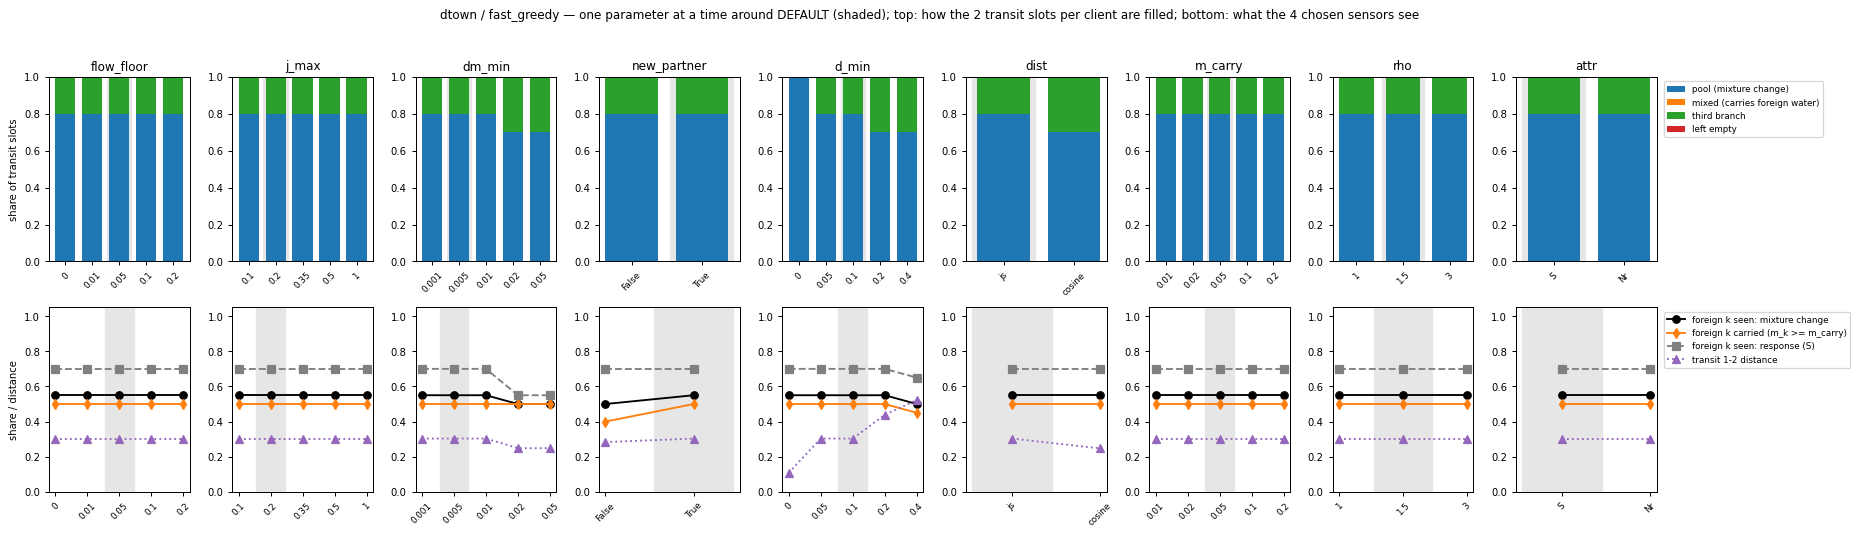

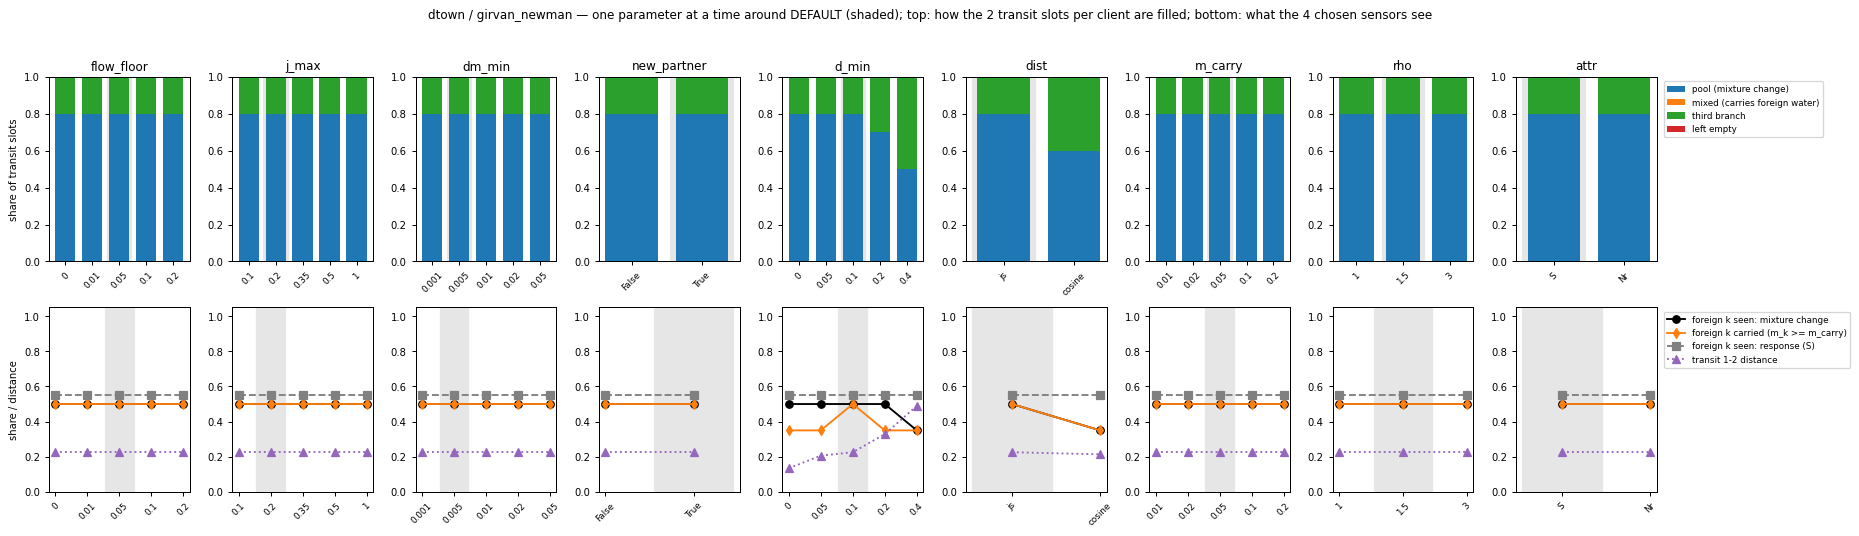

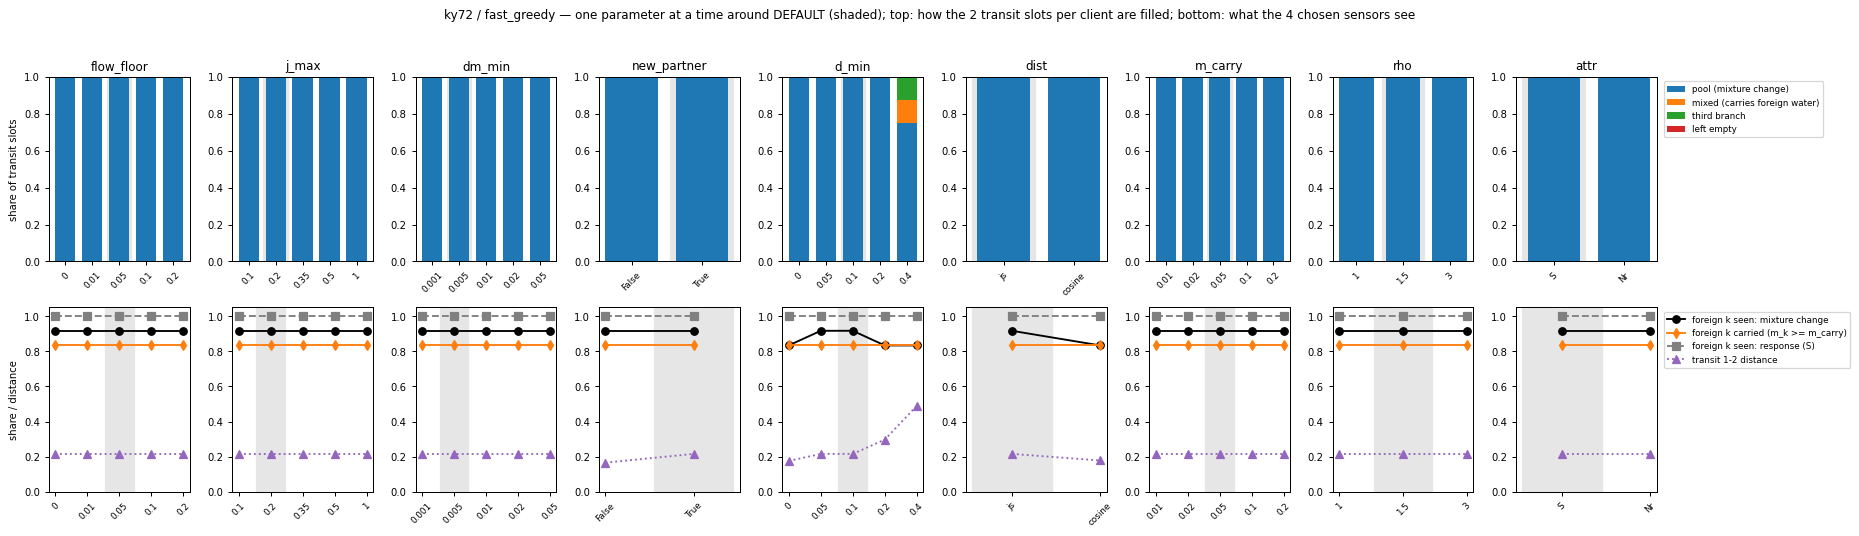

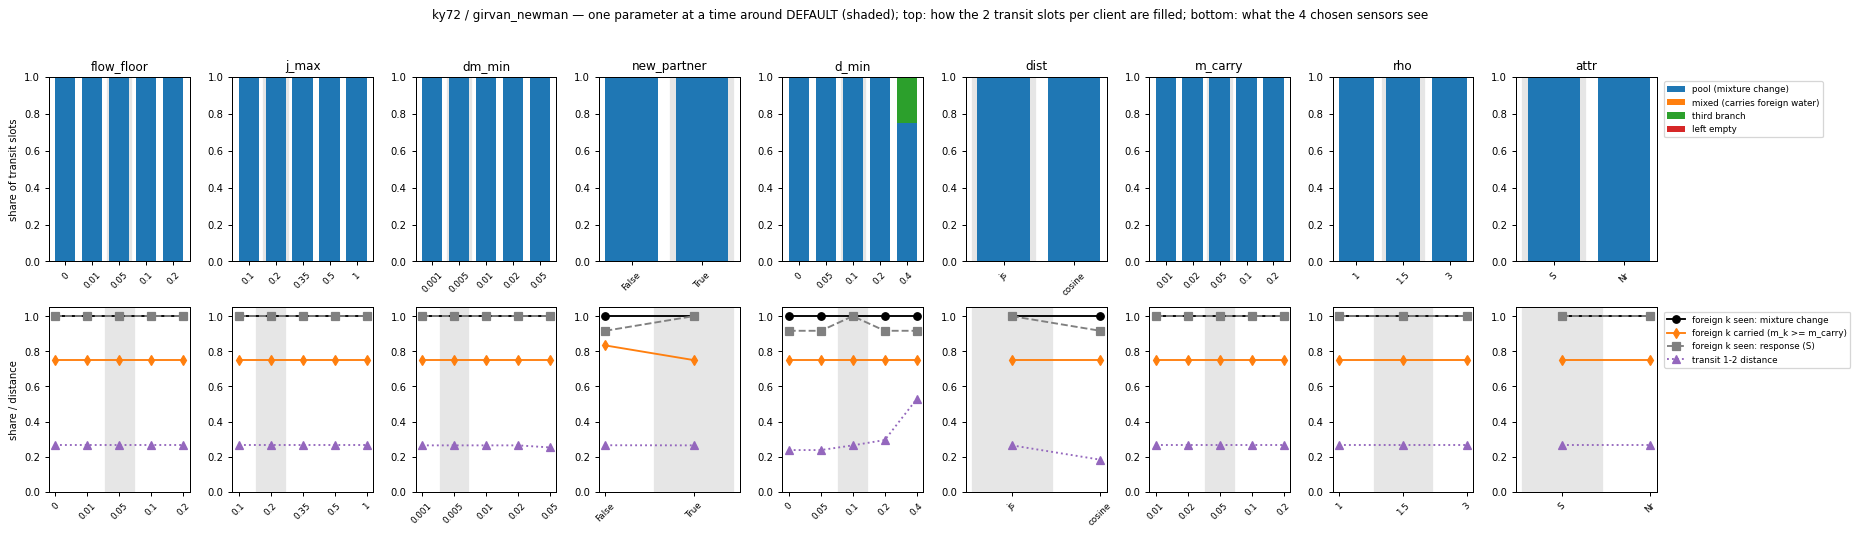

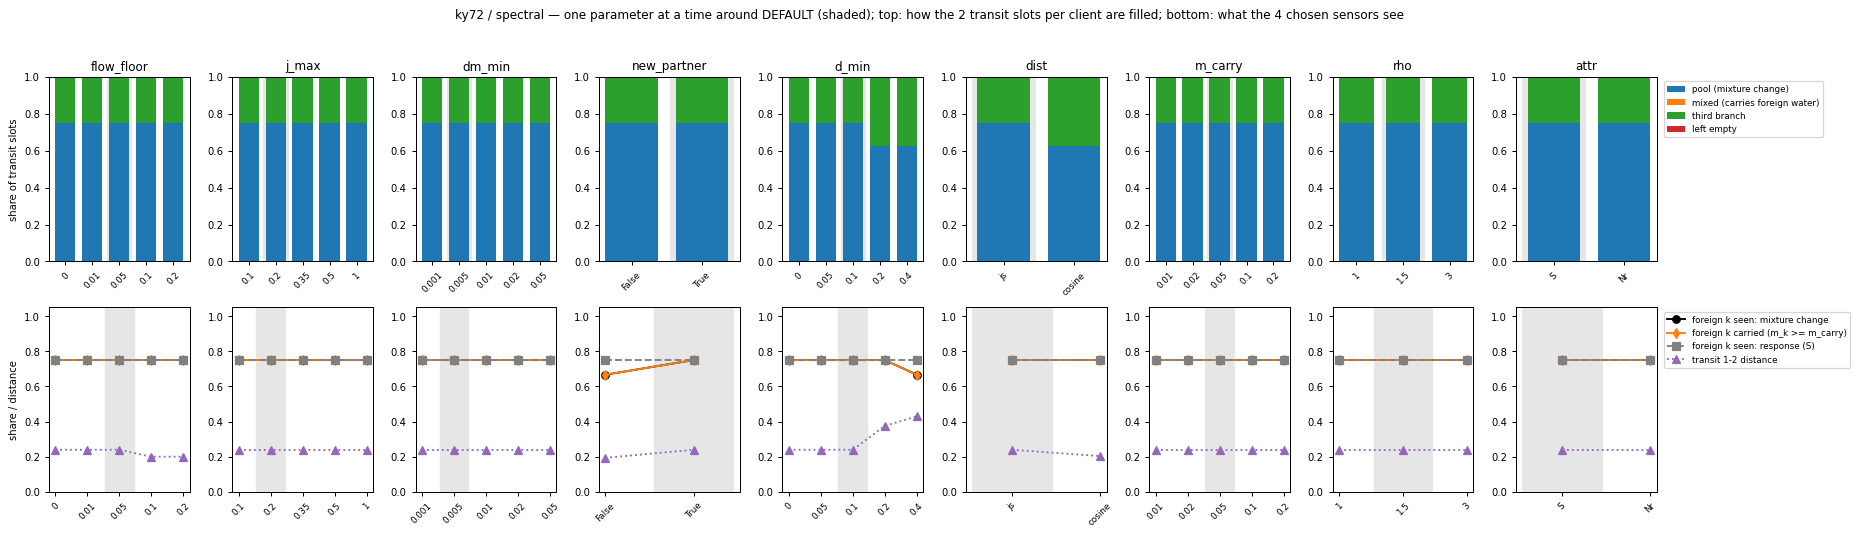

**Sweep table** (shares over all clients of the stack)

transit_pool  transit_mixed  transit_branch_fill  transit_short  branch_short  k_seen_mixture  k_carried  k_seen_response  transit_distance  branch_jaccard_max  pool_size_med  \
network partition     param       value                                                                                                                                                                                    
dtown   fast_greedy   flow_floor  0.0            0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           17.0   
                                  0.01           0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           17.0   
                                  0.05           0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           17.0   
                                  0.1            0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           17.0   
                                  0.2            0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           17.0   
                      j_max       0.1            0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.000           17.0   
                                  0.2            0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           17.0   
                                  0.35           0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.286           17.0   
                                  0.5            0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.500           17.0   
                                  1.0            0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.952           17.0   
                      dm_min      0.001          0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           17.0   
                                  0.005          0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           17.0   
                                  0.01           0.800          0.000                0.200            0.0           0.0           0.550      0.500            0.700             0.304               0.182           14.0   
                                  0.02           0.700          0.000                0.300            0.0           0.0           0.500      0.500            0.550             0.249               0.182            4.0   
                                  0.05           0.700          0.000                0.300            0.0           0.0           0.500      0.500            0.550             0.249               0.182            4.0   
                      new_partner 0.0            0.800          0.000                0.200            0.0           0.0           0.500      0.400            0.700             0.283               0.182           17.0   
                                  1.0            0.800          0.000             

In [5]:
# one-at-a-time sweep around DEFAULT: how the transit slots get filled, and what the chosen set sees
GRID = {"flow_floor": [0.0, 0.01, 0.05, 0.1, 0.2], "j_max": [0.1, 0.2, 0.35, 0.5, 1.0],
        "dm_min": [0.001, 0.005, 0.01, 0.02, 0.05], "new_partner": [False, True], "d_min": [0.0, 0.05, 0.1, 0.2, 0.4],
        "dist": ["js", "cosine"], "m_carry": [0.01, 0.02, 0.05, 0.1, 0.2], "rho": [1.0, 1.5, 3.0], "attr": ["S", "Nr"]}


def summarise(PS, P):
    s, lg = select_flow(PS, P)
    cv = coverage(PS, s)
    n_t, nf = P["n_transit"] * len(lg), cv["n_foreign"].sum()
    return s, lg, cv, {
        "transit_pool": lg["transit_pool"].sum() / n_t, "transit_mixed": lg["transit_mixed"].sum() / n_t,
        "transit_branch_fill": lg["transit_branch_fill"].sum() / n_t, "transit_short": lg["short_transit"].sum() / n_t,
        "branch_short": lg["short_branch"].sum() / (P["n_branch"] * len(lg)),
        "k_seen_mixture": cv["k_seen_mixture"].sum() / nf, "k_carried": cv["k_carried"].sum() / nf,
        "k_seen_response": cv["k_seen_response"].sum() / nf,
        "transit_distance": lg["transit_distance"].mean(), "branch_jaccard_max": lg["branch_jaccard"].max(),
        "pool_size_med": lg["n_transit_pool"].median(), "dm_transit_med": s.loc[s["filled_as"] == "pool", "dm_credit"].abs().median()}


rows = []
for key, PS in PREP.items():
    for par, vals in GRID.items():
        for v in vals:
            *_, met = summarise(PS, {**DEFAULT, par: v})
            rows.append({"network": key[0], "partition": key[1], "param": par, "value": v,
                         "default": v == DEFAULT[par], **met})
SWEEP = pd.DataFrame(rows)
SWEEP.astype({"value": str}).to_parquet(OUT / "sweep.parquet", index=False)

FILL = [("transit_pool", "#1f77b4", "pool (mixture change)"), ("transit_mixed", "#ff7f0e", "mixed (carries foreign water)"),
        ("transit_branch_fill", "#2ca02c", "third branch"), ("transit_short", "#d62728", "left empty")]
keys = list(PREP)
for key in keys:
    q = SWEEP[(SWEEP["network"] == key[0]) & (SWEEP["partition"] == key[1])]
    fig, axes = plt.subplots(2, len(GRID), figsize=(2.3 * len(GRID), 6.0), squeeze=False)
    for j, par in enumerate(GRID):
        g = q[q["param"] == par].reset_index(drop=True)
        x = np.arange(len(g))
        bottom = np.zeros(len(g))
        for col, c_, lab in FILL:
            axes[0, j].bar(x, g[col], bottom=bottom, color=c_, width=0.75, label=lab)
            bottom += g[col].to_numpy()
        axes[1, j].plot(x, g["k_seen_mixture"], "o-", color="k", label="foreign k seen: mixture change")
        axes[1, j].plot(x, g["k_carried"], "d-", color="#ff7f0e", label="foreign k carried (m_k >= m_carry)")
        axes[1, j].plot(x, g["k_seen_response"], "s--", color="0.5", label="foreign k seen: response (S)")
        axes[1, j].plot(x, g["transit_distance"].clip(upper=1), "^:", color="#9467bd", label="transit 1-2 distance")
        for a in axes[:, j]:
            a.set_xticks(x, [f"{v:g}" if isinstance(v, float) else str(v) for v in g["value"]], fontsize=7, rotation=45)
            dx = np.where(g["default"])[0]
            if len(dx):
                a.axvspan(dx[0] - 0.45, dx[0] + 0.45, color="0.9", zorder=0)
        axes[0, j].set(ylim=(0, 1), title=par)
        axes[1, j].set(ylim=(0, 1.05))
    axes[0, 0].set_ylabel("share of transit slots")
    axes[1, 0].set_ylabel("share / distance")
    axes[0, -1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1))
    axes[1, -1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.suptitle(f"{key[0]} / {key[1]} — one parameter at a time around DEFAULT (shaded); top: how the 2 transit "
                 "slots per client are filled; bottom: what the 4 chosen sensors see")
    fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()
display(Markdown("**Sweep table** (shares over all clients of the stack)"))
display(SWEEP.set_index(["network", "partition", "param", "value"]).drop(columns="default").round(3))

## The chosen sets

Per client at `DEFAULT`. The composition bars show where each chosen sensor's water goes (no-drift city); the matrix
next to it, how strongly each drift moves that mixture (log10 $\lvert\Delta m_k\rvert$, own district blank) with the
cell's channel class (Td transit_demand, Th transit_hub, tr trace, Rd reroute_demand, H hub_only).

In [6]:
# the chosen sets at DEFAULT, per client: which links, how they were filled, what they carry and see
NEW, LOGS, CMP = {}, [], []
for key, PS in PREP.items():
    s, lg, cv, _ = summarise(PS, DEFAULT)
    NEW[key] = s
    LOGS.append(lg.merge(cv, on="client").assign(network=key[0], partition=key[1]))
    L, el_ = PS["L"], s["element"]
    CMP.append({"network": key[0], "partition": key[1], "sensors": len(s),
                "carry only own water (no-drift)": int((L.loc[el_, "m_home"] >= 1 - 1e-9).sum()),
                "m_home median": float(L.loc[el_, "m_home"].median()),
                "storage share median": float(L.loc[el_, "c_storage"].median()),
                "foreign k seen (mixture)": cv["k_seen_mixture"].sum() / cv["n_foreign"].sum(),
                "foreign k carried": cv["k_carried"].sum() / cv["n_foreign"].sum(),
                "foreign k seen (response)": cv["k_seen_response"].sum() / cv["n_foreign"].sum()})
LOGS = pd.concat(LOGS, ignore_index=True)
display(Markdown("**Per client, DEFAULT** — pool sizes, how the transit slots were filled, what the chosen set sees"))
display(LOGS.set_index(["network", "partition", "client"]).round(3))
display(Markdown("**Per stack**"))
display(pd.DataFrame(CMP).set_index(["network", "partition"]).round(3))

wide = []
for key in NEW:
    n = NEW[key].assign(pick=lambda d: d["element"] + np.where(d["filled_as"].isin(["branch", "pool"]), "",
                                                               " (" + d["filled_as"] + ")")
                       + np.where(d["credit"].notna(), " → " + d["credit"].fillna("").str.replace("District_", ""), ""))
    wide.append(n.pivot(index="client", columns="slot", values="pick").assign(network=key[0], partition=key[1])
                .reset_index())
display(Markdown("**The picks** (slot -> link; fill route in brackets when not from the pool; → the foreign district "
                 "it is credited to)"))
display(pd.concat(wide, ignore_index=True).set_index(["network", "partition", "client"]))
pd.concat([v.assign(network=k[0], partition=k[1]) for k, v in NEW.items()]).to_parquet(OUT / "selection_new.parquet", index=False)
LOGS.to_parquet(OUT / "selection_log.parquet", index=False)

**Per client, DEFAULT** — pool sizes, how the transit slots were filled, what the chosen set sees

kind  n_candidates  n_branch_pool  n_transit_cand  n_transit_pool  n_mixed_cand  n_branch  transit_pool  transit_mixed  transit_branch_fill  short_branch  short_transit  transit_distance  \
network partition     client                                                                                                                                                                                                   
dtown   fast_greedy   District_A  flow           117             39              78               3             1         2             1              0                    1             0              0             0.470   
                      District_B  flow            97             33              64              17             0         2             1              0                    1             0              0             0.524   
                      District_C  flow            96             24              72              64            53         2             2              0                    0             0              0             0.282   
                      District_D  flow            62             23              39              10            14         2             2              0                    0             0              0             0.127   
                      District_E  flow            50             15              35              35            28         2             2              0                    0             0              0             0.115   
        girvan_newman District_A  flow           105             28              77              21            21         2             2              0                    0             0              0             0.167   
                      District_B  flow           108             35              73               0             0         2             0              0                    2             0              0             0.250   
                      District_C  flow            85             28              57              49            48         2             2              0                    0             0              0             0.343   
                      District_D  flow            61             29              32              17            14         2             2              0                    0             0              0             0.194   
                      District_E  flow            61             11              50              42            39         2             2              0                    0             0              0             0.175   
ky72    fast_greedy   District_A  flow           209             13             196             187           185         2             2              0                    0             0              0             0.342   
                      District_B  flow           165             28             137             117            93         2             2              0                    0             0              0             0.190   
                      District_C  flow            93             52              41              22            21         2             2              0                    0             0              0             0.142   
                      District_D  flow            82             21              61              43            36         2             2              0                    0             0              0             0.191   
        girvan_newman District_A  flow           290             47             243             233           225         2             2              0                    0             0              0             0.499   
                      District_B  flow            97             25              72              60            16         2             2              0                    0             0              0             0.198   
  

**Per stack**

sensors  carry only own water (no-drift)  m_home median  storage share median  foreign k seen (mixture)  foreign k carried  foreign k seen (response)
network partition                                                                                                                                                           
dtown   fast_greedy         20                               12          1.000                 0.000                     0.550              0.500                       0.70
        girvan_newman       20                               13          1.000                 0.000                     0.500              0.500                       0.55
ky72    fast_greedy         16                                8          0.842                 0.119                     0.917              0.833                       1.00
        girvan_newman       16                                8          0.938                 0.108                     1.000              0.750                       1.00
        spectral            16                                9          1.000                 0.000                     0.750              0.750                       0.75

**The picks** (slot -> link; fill route in brackets when not from the pool; → the foreign district it is credited to)

slot                             q_branch_0 q_branch_1          q_transit_0          q_transit_1
network partition     client                                                                    
dtown   fast_greedy   District_A       P633       P781             P995 → C   P981 (branch_fill)
                      District_B      P1033      P1024             P341 → D   P142 (branch_fill)
                      District_C         P5       P295             P235 → A              P18 → B
                      District_D       P794       P800             P215 → B             P468 → B
                      District_E       P125       P924              P99 → B             P108 → C
        girvan_newman District_A       P794       P142             P215 → D             P468 → D
                      District_B       P633       P781   P981 (branch_fill)   P811 (branch_fill)
                      District_C       P125       P295             P443 → A              P18 → B
                      District_D      P1033      P1024             P524 → A             P336 → A
                      District_E         P5        P10             P159 → B              P15 → B
ky72    fast_greedy   District_A      P-389      P-475            P-122 → D            P-398 → C
                      District_B       P-30       P-38            P-617 → A            P-297 → C
                      District_C       P-63      P-250             P-22 → D             P-34 → B
                      District_D      P-351        P-8            P-431 → A            P-491 → A
        girvan_newman District_A       P-63      P-250            P-368 → D            P-174 → B
                      District_B       P-30       P-38             P-52 → A            P-596 → C
                      District_C      P-389      P-475            P-466 → A            P-598 → B
                      District_D       P-51      P-556             P-10 → A             P-29 → C
        spectral      District_A       P-63      P-351            P-598 → B            P-372 → D
                      District_B       P-30       P-38            P-323 → A            P-297 → D
                      District_C      P-389      P-475            P-571 → A            P-495 → A
                      District_D       P-39      P-250  P-312 (branch_fill)  P-227 (branch_fill)

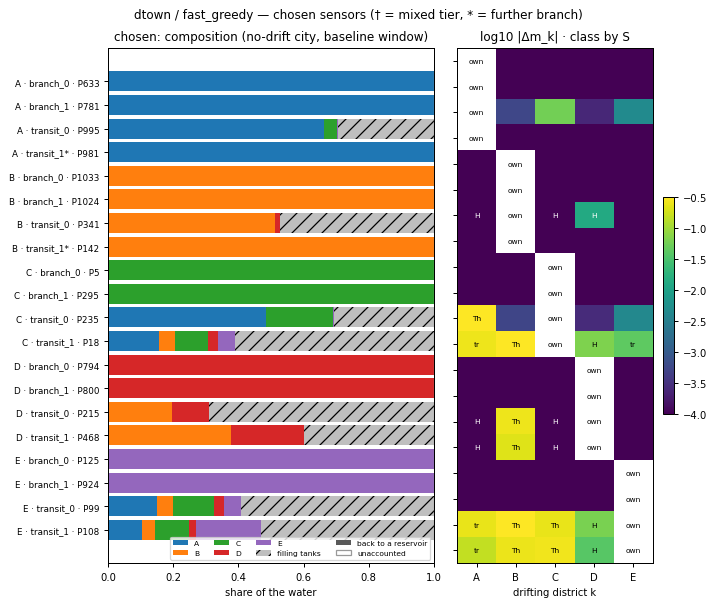

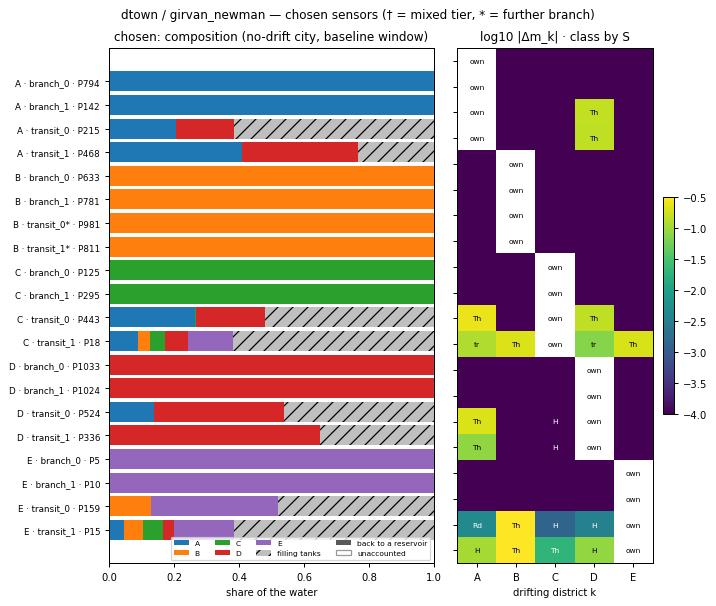

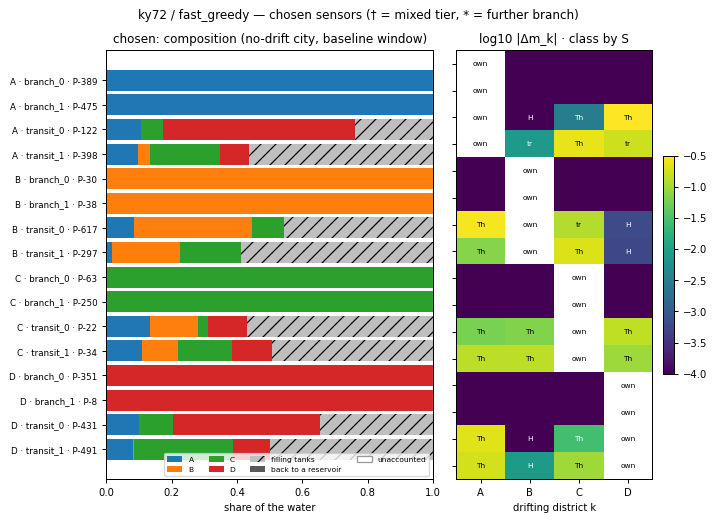

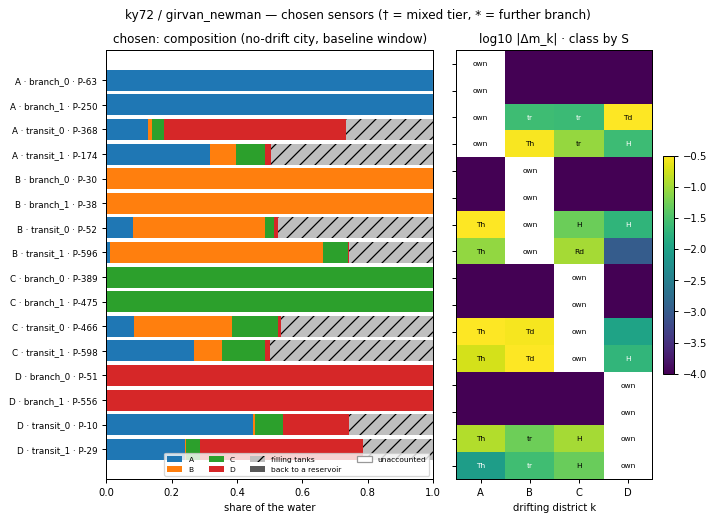

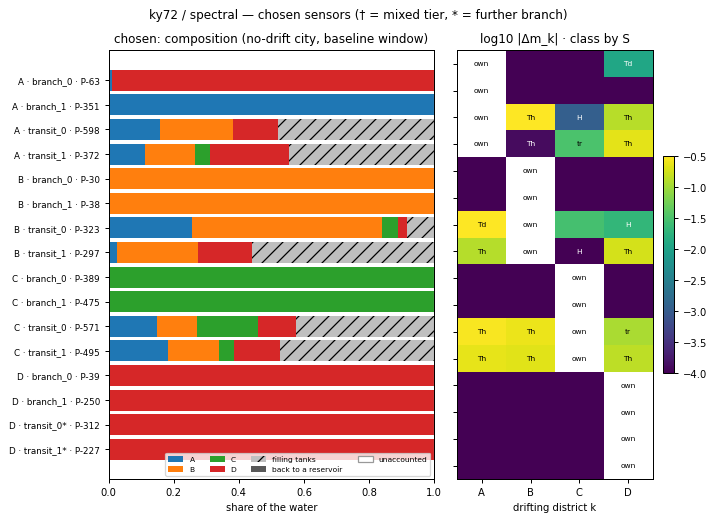

In [7]:
# where each chosen sensor's water goes (no-drift city, baseline window) and how its mixture moves under each drift
cmap = plt.get_cmap("tab10")
for key, PS in PREP.items():
    names, L = PS["names"], PS["L"]
    sets = [("chosen", NEW[key].assign(tag=lambda d: d["slot"].str.replace("q_", "") + np.where(
        d["filled_as"] == "mixed", "†", np.where(d["filled_as"] == "branch_fill", "*", ""))))]
    n = max(len(s) for _, s in sets)
    fig, axes = plt.subplots(1, 2 * len(sets), figsize=(8 * len(sets), 0.24 * n + 2),
                             gridspec_kw={"width_ratios": [3, 2] * len(sets)}, squeeze=False)
    for j, (rule, chs) in enumerate(sets):
        chs = chs.sort_values(["client", "tag"]).reset_index(drop=True)
        y = np.arange(len(chs))
        ax = axes[0, 2 * j]
        left = np.zeros(len(chs))
        parts = [(f"c_{d}", cmap(i), d.replace("District_", "")) for i, d in enumerate(names)] + \
                [("c_storage", "0.75", "filling tanks"), ("c_reservoir", "0.35", "back to a reservoir"),
                 ("c_unaccounted", "white", "unaccounted")]
        for col, c_, lab in parts:
            v = chs["element"].map(L[col]).fillna(0).to_numpy(float)
            ax.barh(y, v, left=left, color=c_, edgecolor="0.6" if col == "c_unaccounted" else None,
                    hatch="//" if col == "c_storage" else None, label=lab, height=0.85)
            left += v
        lab_ = [f"{c.replace('District_', '')} · {t} · {e}" + (" (pump)" if L.at[e, "is_pump"] else "")
                + (" (valve)" if L.at[e, "is_valve"] else "") for c, t, e in zip(chs["client"], chs["tag"], chs["element"])]
        ax.set_yticks(y, lab_, fontsize=7)
        ax.invert_yaxis()
        ax.set(xlim=(0, 1), title=f"{rule}: composition (no-drift city, baseline window)", xlabel="share of the water")
        ax.legend(fontsize=6, ncol=4, loc="lower right")
        ax2 = axes[0, 2 * j + 1]
        Z = PS["DM"].loc[list(chs["element"]), names].abs()
        own = np.array([[k == c for k in names] for c in chs["client"]])
        Zl = np.log10(np.clip(Z.to_numpy(float), 1e-4, 1.0))
        Zl[own] = np.nan
        im = ax2.imshow(Zl, aspect="auto", cmap="viridis", vmin=-4, vmax=-0.5, interpolation="nearest")
        cls = PS["CLS"]["S"].loc[list(chs["element"]), names].to_numpy()
        abbr = {"transit_demand": "Td", "transit_hub": "Th", "trace": "tr", "reroute_demand": "Rd",
                "hub_only": "H", "undefined": "?", "none": "", "own": "own"}
        for (i, k), c_ in np.ndenumerate(cls):
            ax2.text(k, i, abbr.get(c_, ""), ha="center", va="center", fontsize=6,
                     color="w" if not own[i, k] and np.nan_to_num(Zl[i, k], nan=-4) < -1.5 else "k")
        ax2.set_xticks(range(len(names)), [d.replace("District_", "") for d in names])
        ax2.set_yticks(y, [""] * len(y))
        ax2.set(title="log10 |Δm_k| · class by S", xlabel="drifting district k")
        fig.colorbar(im, ax=ax2, fraction=0.05)
    fig.suptitle(f"{key[0]} / {key[1]} — chosen sensors († = mixed tier, * = further branch)")
    fig.tight_layout(); plt.show()

### Client × drifting district

Colour: the largest mixture change $\lvert\Delta m_k\rvert$ over the client's sensors (log10); number: how many of its sensors respond
($S\ge$ floor). A row with dark cells everywhere is a client whose set cannot see its neighbours' drift.

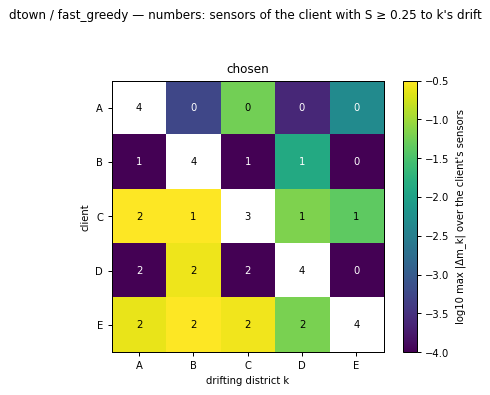

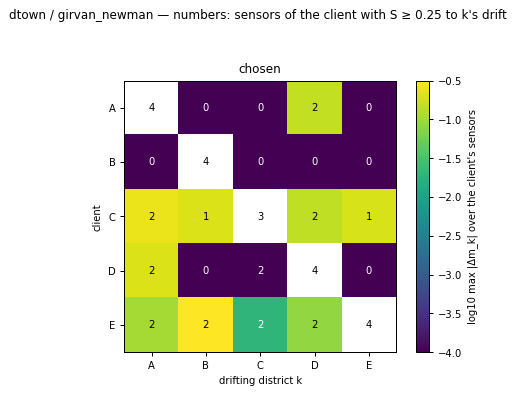

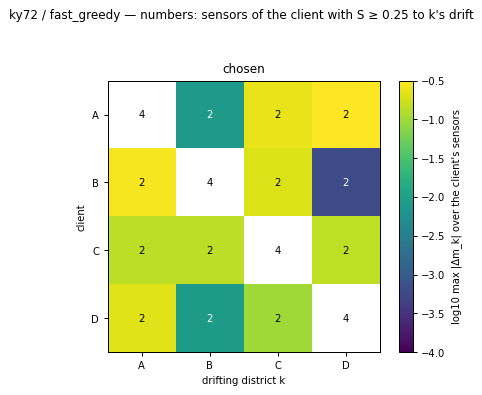

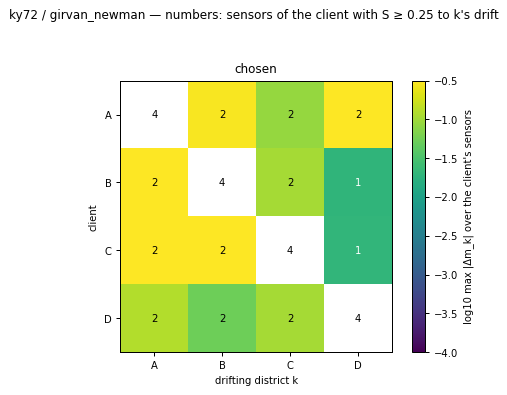

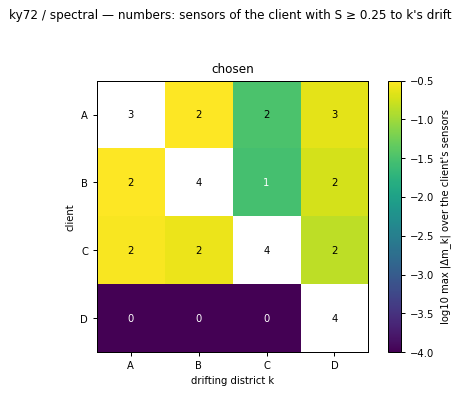

In [8]:
# client x drifting district: does any of the client's sensors see k's drift change its water (colour), and how many
# of them respond to it at all (S >= floor, number)?
for key, PS in PREP.items():
    names = PS["names"]
    sets = [("chosen", NEW[key])]
    fig, axes = plt.subplots(1, len(sets), figsize=(5.2 * len(sets), 4.4), squeeze=False)
    for j, (rule, chs) in enumerate(sets):
        M = np.full((len(names), len(names)), np.nan)
        N = np.zeros((len(names), len(names)), int)
        for i, h in enumerate(names):
            el_ = list(chs.loc[chs["client"] == h, "element"])
            if not el_:
                continue
            M[i] = np.log10(np.clip(PS["DM"].loc[el_, names].abs().max(axis=0).to_numpy(float), 1e-4, 1.0))
            N[i] = (PS["S"].loc[el_, names] >= FLOOR["S"]).sum(axis=0).to_numpy()
        np.fill_diagonal(M, np.nan)
        ax = axes[0, j]
        im = ax.imshow(M, cmap="viridis", vmin=-4, vmax=-0.5)
        for (i, k), v in np.ndenumerate(N):
            ax.text(k, i, str(v), ha="center", va="center", fontsize=8,
                    color="w" if i != k and np.nan_to_num(M[i, k], nan=-4) < -1.5 else "k")
        lab = [d.replace("District_", "") for d in names]
        ax.set_xticks(range(len(names)), lab)
        ax.set_yticks(range(len(names)), lab)
        ax.set(xlabel="drifting district k", ylabel="client", title=f"{rule}")
        fig.colorbar(im, ax=ax, fraction=0.046, label="log10 max |Δm_k| over the client's sensors")
    fig.suptitle(f"{key[0]} / {key[1]} — numbers: sensors of the client with S ≥ {FLOOR['S']:g} to k's drift")
    fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

### Maps

Links coloured by topology (branch blue, source bridge orange, loop grey), nodes by district, tanks and reservoirs
as black diamonds; ▲ branch, ★ transit.

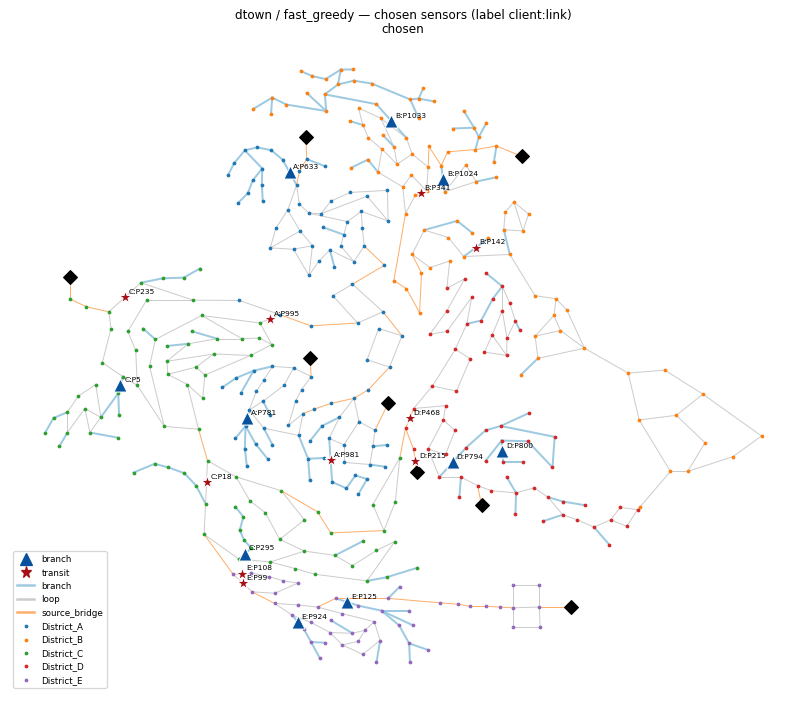

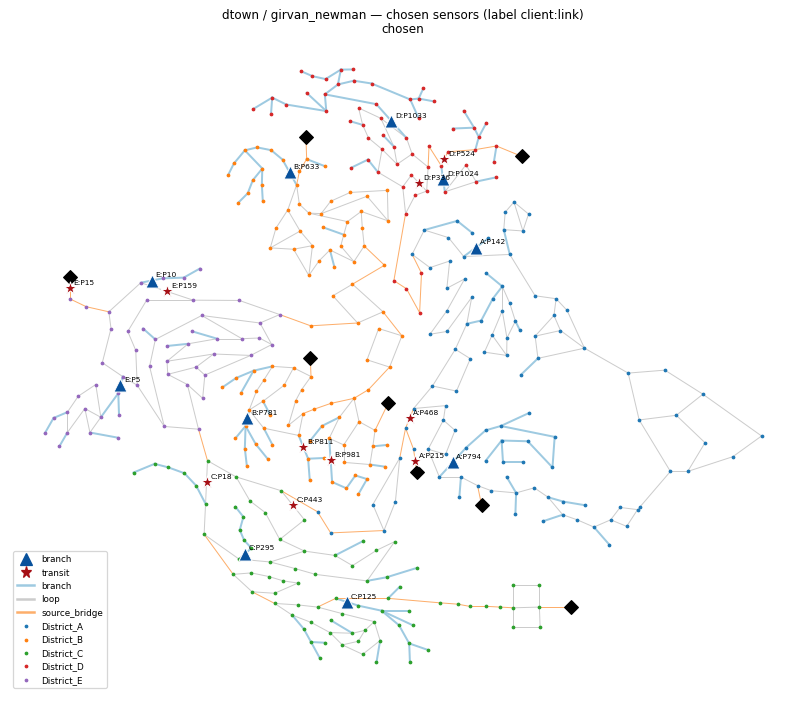

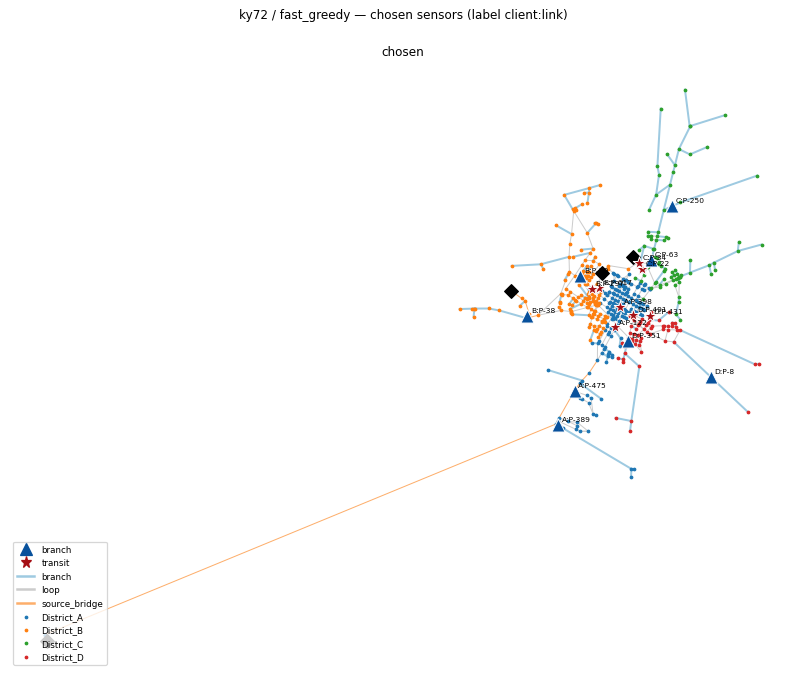

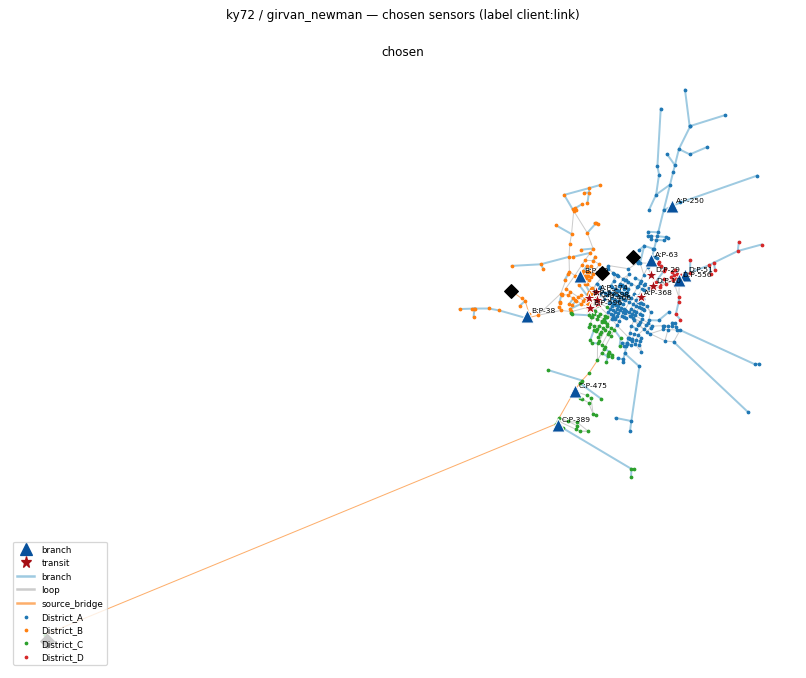

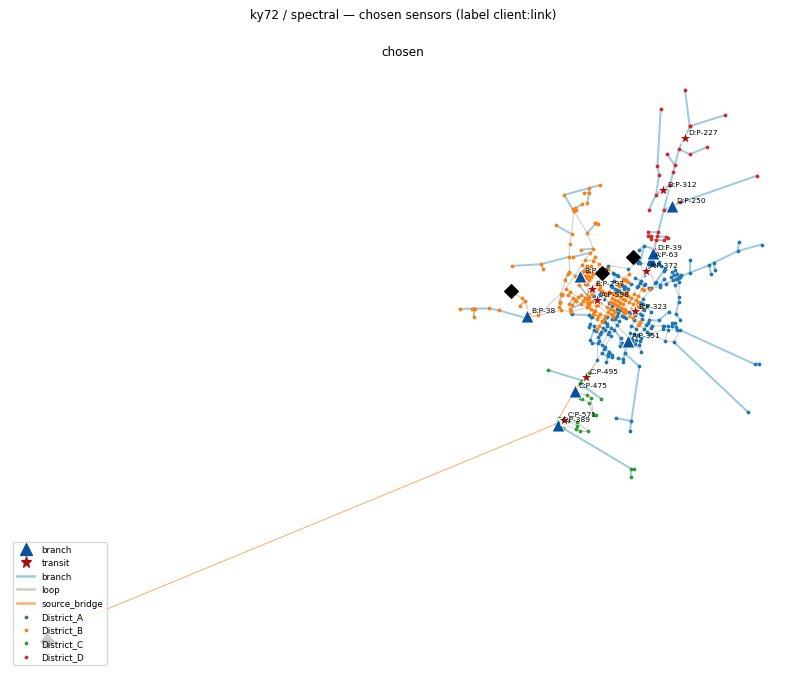

In [9]:
# the chosen sensors on the network (node colour = district; link colour = topology class)
TOPO_COL = {"branch": "#9ecae1", "loop": "0.8", "source_bridge": "#fdae6b", "isolated": "0.9"}
MARK = {"branch": ("^", "#08519c"), "transit": ("*", "#a50f15")}
for key, X in XS.items():
    PS = PREP[key]
    owner = X["path"].parents[1]
    with open(owner / "worlds" / PS["names"][0] / "wn.pkl", "rb") as fh:
        wn = pickle.load(fh)
    xy = {n: wn.get_node(n).coordinates for n in wn.node_name_list}
    if not any(c and (c[0] or c[1]) for c in xy.values()):
        display(Markdown(f"{key}: the model has no coordinates — map skipped")); continue
    L = PS["L"]
    n2d = {str(n): d for d, ns in yaml.safe_load((owner / "districts.yml").read_text())["districts"].items() for n in ns}
    sets = [("chosen", NEW[key].assign(kind=lambda d: d["slot"].str.split("_").str[1]), "kind")]
    fig, axes = plt.subplots(1, len(sets), figsize=(9 * len(sets), 8), squeeze=False)
    for j, (rule, chs, kcol) in enumerate(sets):
        ax = axes[0, j]
        for ln in wn.link_name_list:
            u, v = L.at[ln, "start"], L.at[ln, "end"]
            ax.plot([xy[u][0], xy[v][0]], [xy[u][1], xy[v][1]], color=TOPO_COL.get(L.at[ln, "topo"], "0.8"),
                    lw=1.6 if L.at[ln, "topo"] == "branch" else 0.8, zorder=1)
        for i, d in enumerate(PS["names"]):
            pts = np.array([xy[n] for n, dd in n2d.items() if dd == d and n in xy])
            if len(pts):
                ax.scatter(pts[:, 0], pts[:, 1], s=4, color=plt.get_cmap("tab10")(i), zorder=2, label=d)
        for t in list(wn.tank_name_list) + list(wn.reservoir_name_list):
            ax.scatter(*xy[t], s=60, marker="D", color="k", zorder=3)
        for _, r in chs.iterrows():
            e = r["element"]
            u, v = L.at[e, "start"], L.at[e, "end"]
            mx, my = (xy[u][0] + xy[v][0]) / 2, (xy[u][1] + xy[v][1]) / 2
            m_, c_ = MARK.get(r[kcol], ("x", "k"))
            ax.scatter(mx, my, s=110, marker=m_, color=c_, edgecolor="w", lw=0.8, zorder=4)
            ax.annotate(f"{r['client'].replace('District_', '')}:{e}", (mx, my), fontsize=6, xytext=(3, 3),
                        textcoords="offset points", zorder=5)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title(f"{rule}")
        h = [Line2D([], [], marker=MARK[k][0], color=MARK[k][1], ls="", ms=9, label=k)
             for k in ("branch", "transit")]
        h += [Line2D([], [], color=c_, lw=2, label=t) for t, c_ in TOPO_COL.items() if t != "isolated"]
        ax.legend(handles=h + ax.get_legend_handles_labels()[0][:len(PS["names"])], fontsize=7, loc="lower left")
    fig.suptitle(f"{key[0]} / {key[1]} — chosen sensors (label client:link)")
    fig.tight_layout(); plt.show()

## Rank check

Is each chosen sensor among its client's candidates with the largest drift effect? For every chosen sensor $s$ of client
$h$ and every foreign $k$: its percentile among all of $h$'s live links (every topology) on $\lvert\Delta m_k\rvert$,
$S_k$, $\lvert g_{w,k}\rvert$ and amp$_k$ = the share of the client's candidates with a strictly smaller value (≈1 = the
largest in the client). Only (client, $k$) pairs where some candidate has an effect are scored (the client's largest value
≥ `EFFECT_MIN`): where nothing in the client moves, every candidate ties at ~0 and a "top hit" would be free. Per scored
pair: whether the set holds the client's top candidate, and the best percentile in the set. Branches carry no foreign
water, so their foreign effect is 0 by physics (G-X3). Per-sensor rows in `rank_check.parquet`.

**Share of (client, foreign k) pairs where some candidate has an effect** (only these are scored below)

metric                  S_k  amp_k  |g_w,k|  |Δm_k|
network partition                                  
dtown   fast_greedy    0.75   1.00     1.00    0.55
        girvan_newman  0.60   1.00     1.00    0.50
ky72    fast_greedy    1.00   1.00     1.00    0.92
        girvan_newman  1.00   1.00     1.00    1.00
        spectral       0.75   0.75     0.75    0.75

**On those pairs: does the chosen set hold the client's top candidate (share), and its best percentile (median)** — percentile = share of the client's candidates with a strictly smaller value

top_hit                      best_pct_med                      pairs                     
metric                    S_k amp_k |g_w,k| |Δm_k|          S_k amp_k |g_w,k| |Δm_k|   S_k amp_k |g_w,k| |Δm_k|
network partition                                                                                              
dtown   fast_greedy      0.00  0.05    0.05   0.82         0.82  0.93    0.84   0.98    15    20      20     11
        girvan_newman    0.00  0.15    0.10   0.60         0.86  0.86    0.86   0.98    12    20      20     10
ky72    fast_greedy      0.00  0.25    0.08   0.91         0.73  0.87    0.88   0.99    12    12      12     11
        girvan_newman    0.17  0.08    0.17   0.67         0.92  0.79    0.87   0.98    12    12      12     12
        spectral         0.11  0.00    0.22   0.78         0.85  0.82    0.79   0.97     9     9       9      9

**Median percentile per slot family** (sensors × foreign k, scored pairs only)

metric                          S_k  amp_k  |g_w,k|  |Δm_k|
network partition     family                               
dtown   fast_greedy   branch   0.25   0.32     0.32    0.00
                      transit  0.74   0.80     0.72    0.91
        girvan_newman branch   0.17   0.31     0.31    0.00
                      transit  0.77   0.80     0.75    0.90
ky72    fast_greedy   branch   0.08   0.22     0.22    0.00
                      transit  0.70   0.77     0.79    0.95
        girvan_newman branch   0.11   0.28     0.28    0.00
                      transit  0.83   0.76     0.81    0.92
        spectral      branch   0.08   0.24     0.24    0.00
                      transit  0.68   0.74     0.72    0.86

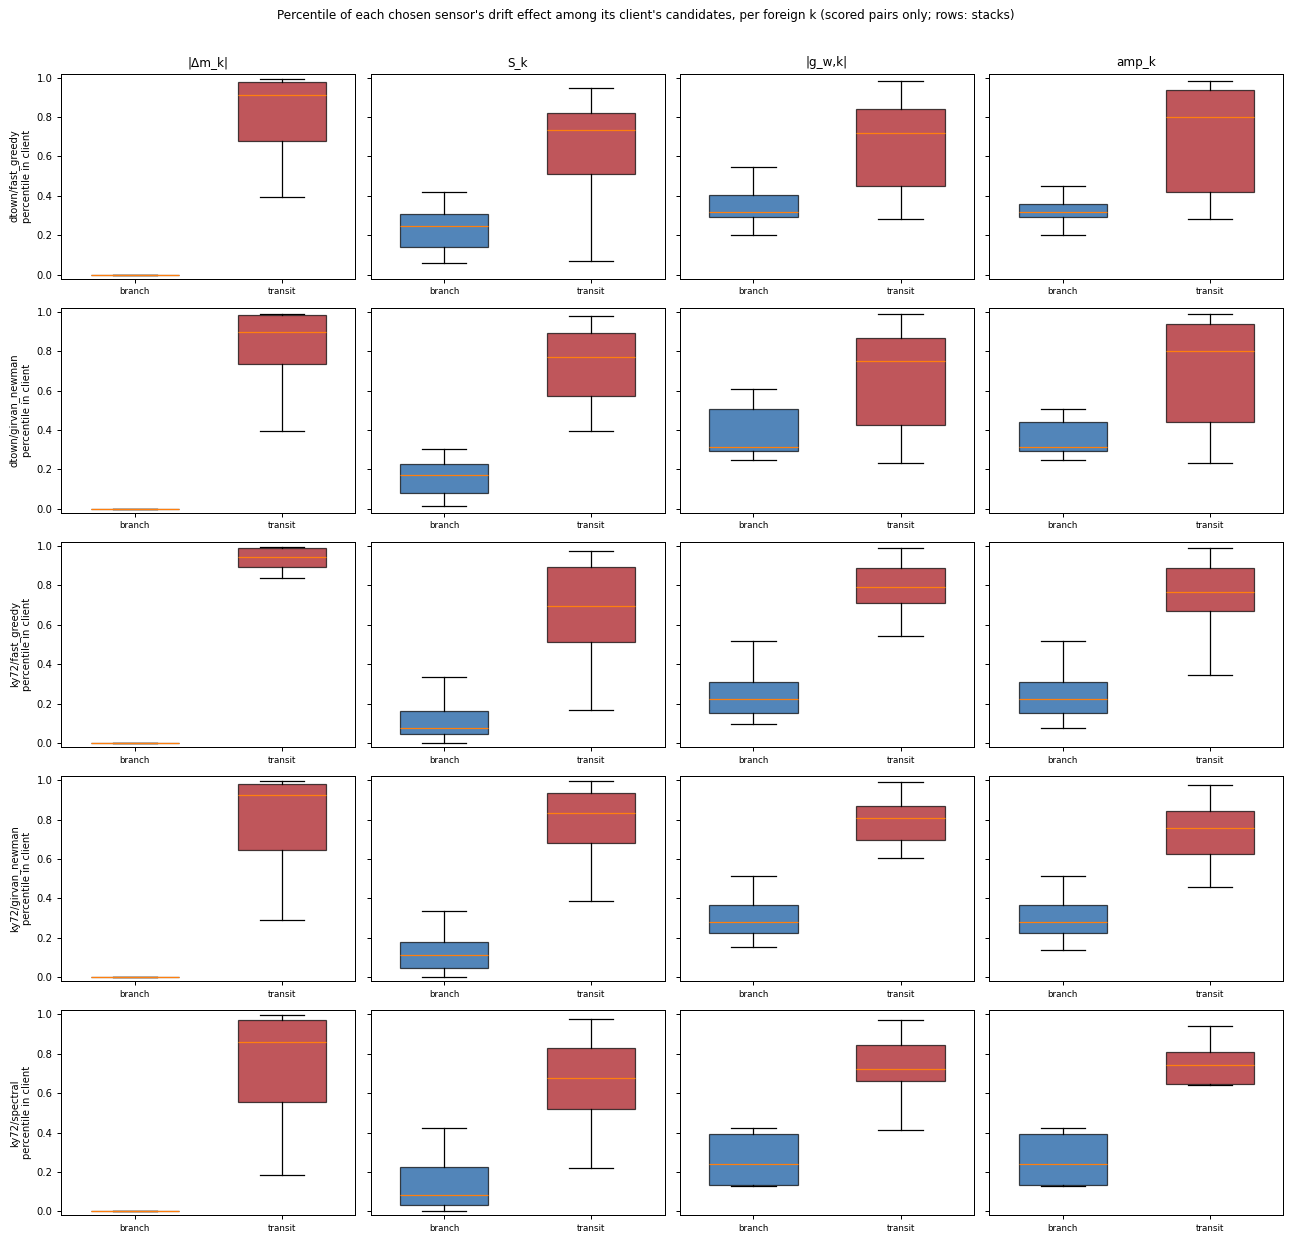

In [10]:
# rank check: where does each chosen sensor rank among its client's candidates, per foreign drifting district k?
# candidates = every live link of the client (placement.select.candidates: not a pump / valve / dead, above the
# flow floor; all topologies). Scored only on (client, k) pairs where some candidate has an effect at all
# (`has_effect`: the client's largest value >= EFFECT_MIN) -- elsewhere every candidate ties at ~0.
EFFECT_MIN = {"|Δm_k|": DEFAULT["dm_min"], "S_k": FLOOR["S"], "|g_w,k|": 1e-3, "amp_k": 1e-3}


def metric_mats(PS):
    return {"|Δm_k|": PS["DM"].abs(), "S_k": PS["S"], "|g_w,k|": PS["GW"].abs(), "amp_k": PS["AMP"]}


RK = []
for key, PS in PREP.items():
    mats = metric_mats(PS)
    live = sel.candidates(PS, {k: DEFAULT[k] for k in sel.RULE_DEFAULTS})
    chosen = NEW[key].assign(family=lambda d: d["slot"].str.split("_").str[1])
    for h, g in chosen.groupby("client"):
        cand = list(live.index[live["home"] == h])
        for k in [d for d in PS["names"] if d != h]:
            for mname, M in mats.items():
                cv = M.loc[cand, k].to_numpy(float)
                cv = cv[np.isfinite(cv)]
                top = cv.max() if len(cv) else np.nan
                for _, r in g.iterrows():
                    v = float(M.at[r["element"], k])
                    RK.append({"network": key[0], "partition": key[1], "client": h, "family": r["family"],
                               "slot": r["slot"], "element": r["element"], "k": k, "metric": mname, "value": v,
                               "pct": np.sum(cv < v) / len(cv) if len(cv) and np.isfinite(v) else np.nan,
                               "is_top": bool(np.isfinite(v) and v >= top), "n_cand": len(cv),
                               "client_max": top, "has_effect": bool(np.isfinite(top) and top >= EFFECT_MIN[mname])})
RK = pd.DataFrame(RK)
RK.to_parquet(OUT / "rank_check.parquet", index=False)

pairs = RK.groupby(["network", "partition", "client", "k", "metric"]).agg(
    has_effect=("has_effect", "first"), hit=("is_top", "any"), best_pct=("pct", "max"))
display(Markdown("**Share of (client, foreign k) pairs where some candidate has an effect** (only these are scored below)"))
display(pairs.groupby(["network", "partition", "metric"])["has_effect"].mean().unstack("metric").round(2))
E = pairs[pairs["has_effect"]]
display(Markdown("**On those pairs: does the chosen set hold the client's top candidate (share), and its best percentile "
                 "(median)** — percentile = share of the client's candidates with a strictly smaller value"))
display(E.groupby(["network", "partition", "metric"]).agg(top_hit=("hit", "mean"), best_pct_med=("best_pct", "median"),
                                                          pairs=("hit", "size")).unstack("metric").round(2))
R = RK[RK["has_effect"]]
display(Markdown("**Median percentile per slot family** (sensors × foreign k, scored pairs only)"))
display(R.pivot_table(index=["network", "partition", "family"], columns="metric", values="pct",
                      aggfunc="median").round(2))

FAM = [("branch", "#08519c"), ("transit", "#a50f15")]
mets = list(EFFECT_MIN)
keys_ = list(PREP)
fig, axes = plt.subplots(len(keys_), len(mets), figsize=(3.6 * len(mets), 2.8 * len(keys_)), squeeze=False, sharey=True)
for i, key in enumerate(keys_):
    q = R[(R["network"] == key[0]) & (R["partition"] == key[1])]
    for j, mname in enumerate(mets):
        ax = axes[i, j]
        data = [q[(q["family"] == f_) & (q["metric"] == mname)]["pct"].dropna() for f_, _ in FAM]
        bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False)
        for b, (_, c_) in zip(bp["boxes"], FAM):
            b.set(facecolor=c_, alpha=0.7)
        ax.set_xticks(range(1, len(FAM) + 1), [f_ for f_, _ in FAM], fontsize=7)
        ax.set_ylim(-0.02, 1.02)
        if i == 0:
            ax.set_title(mname)
        if j == 0:
            ax.set_ylabel(f"{key[0]}/{key[1]}\npercentile in client")
fig.suptitle("Percentile of each chosen sensor's drift effect among its client's candidates, per foreign k "
             "(scored pairs only; rows: stacks)")
fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

## Reading it

Defaults are the pipeline's (`sensor_placement.selection`). A setting worth changing shows up here as a plateau that
does not contain the default, or as a client that the default leaves short. Clients ending with four branches have no
loop carrying foreign water (physics, not the rule).